--- Información volumétrica de archivos ---
lap_times.csv   | Filas:  639293 | Columnas:  6
results.csv     | Filas:   26313 | Columnas: 18
races.csv       | Filas:    1169 | Columnas: 18
circuits.csv    | Filas:      78 | Columnas:  9
pit_stops.csv   | Filas:   13029 | Columnas:  7
status.csv      | Filas:     136 | Columnas:  2


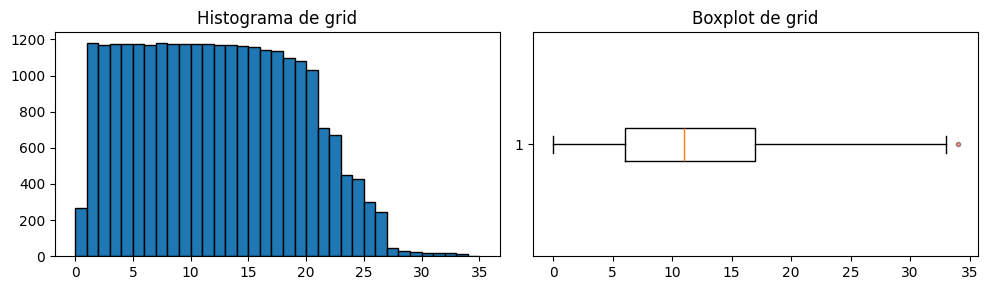

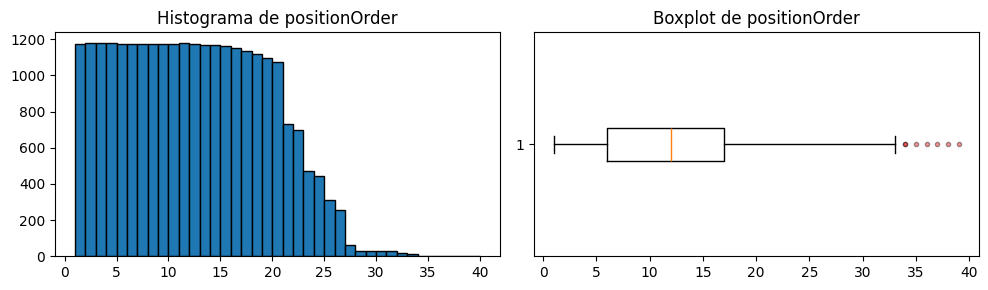

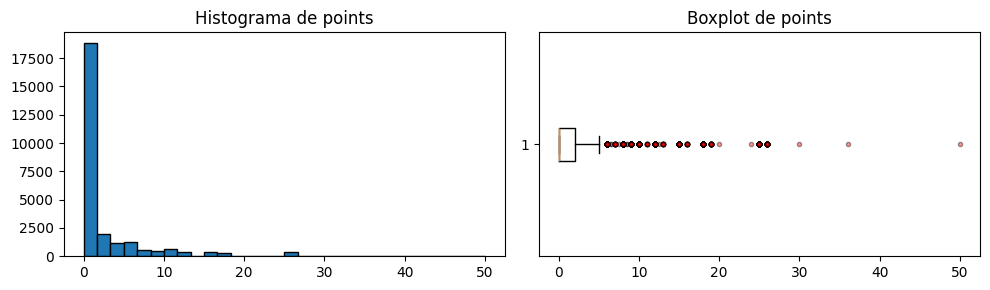

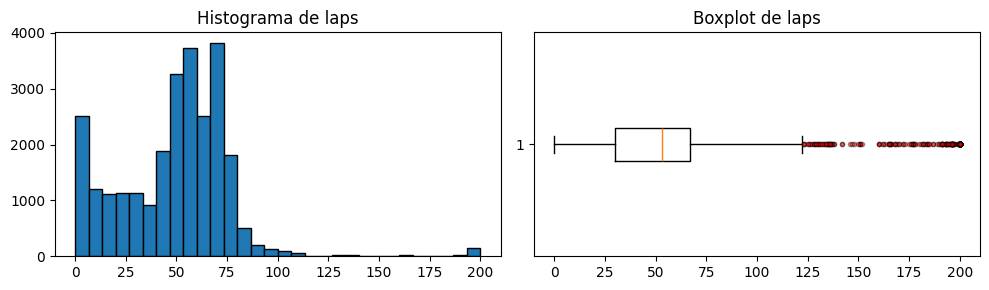

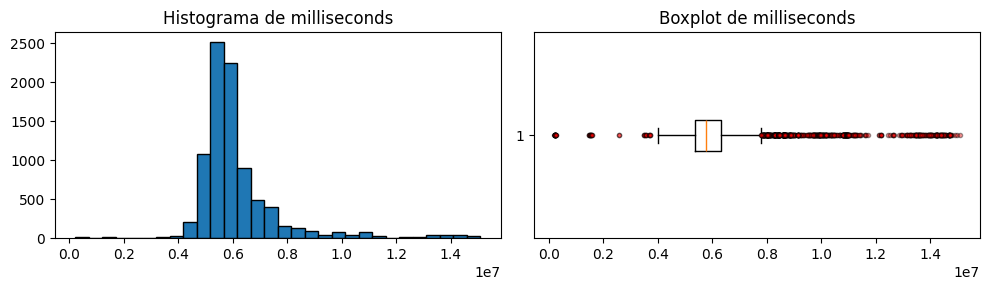

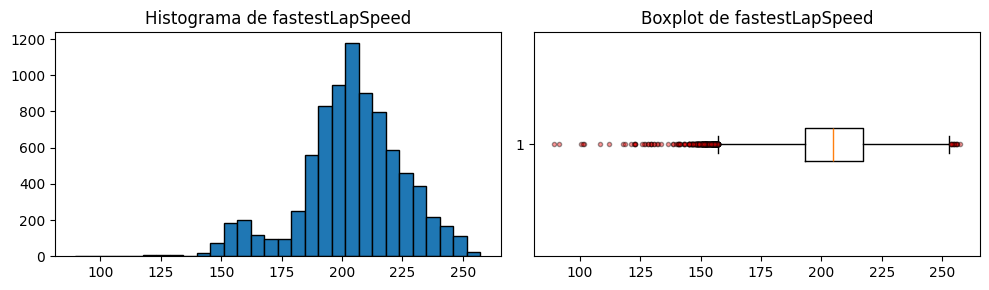

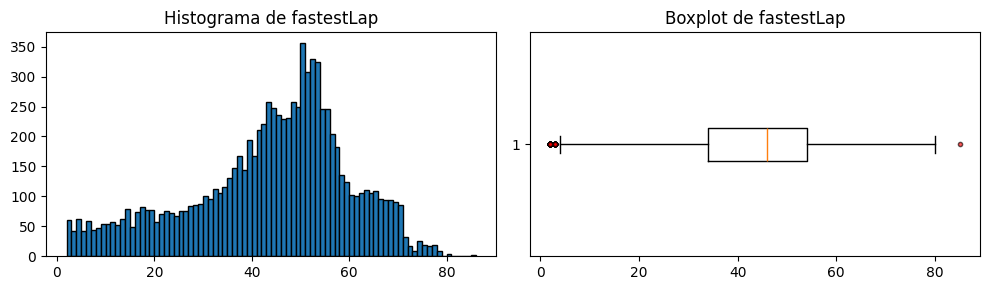

,grid,positionOrder,points,laps,milliseconds,fastestLapSpeed,fastestLap
conteo,26313,26313,26313,26313,8687,8238,9151
min,0,1,0.0,0,207071.0,89.54,2.0
max,34,39,50.0,200,15090540.0,257.32,85.0
media,11.707787,11.929427,2.190228,48.985292,6143009.704041,204.091558,43.048519
mediana,11.0,12.0,0.0,53.0,5754934.0,204.88,46.0
moda,1,"3, 4",0.0,0,14259460.0,207.069,50.0
rango,34,38,50.0,200,14883469.0,167.78,83.0
Q1,6.0,6.0,0.0,30.0,5352097.0,193.30625,34.0
Q2,11.0,12.0,0.0,53.0,5754934.0,204.88,46.0
Q3,17.0,17.0,2.0,67.0,6333194.5,217.26575,54.0



====== Atributo: status ======



,frecuencia,%
status,,
Finished,8227,31.27
+1 Lap,3850,14.63
Engine,2011,7.64
+2 Laps,1593,6.05
Accident,1047,3.98
Collision,833,3.17
Gearbox,805,3.06
Spun off,792,3.01
+3 Laps,731,2.78


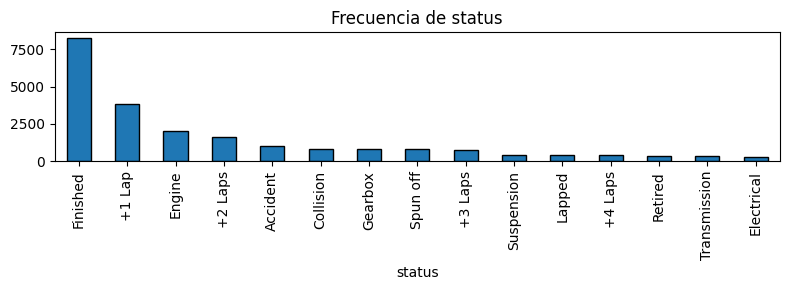


====== Atributo: number ======



,frecuencia,%
number,,
16.0,1043,3.96
6.0,1031,3.92
4.0,1021,3.88
11.0,1017,3.87
3.0,1006,3.82
5.0,999,3.80
14.0,982,3.73
8.0,973,3.70
10.0,965,3.67


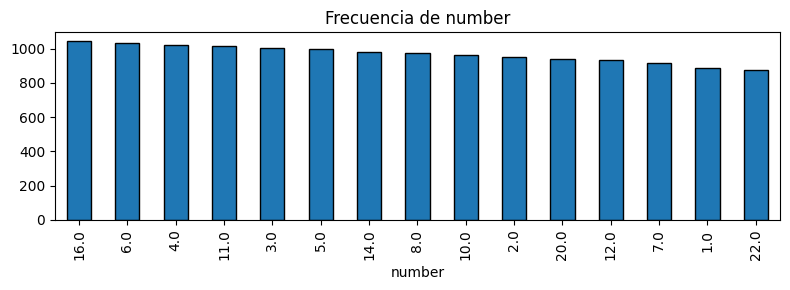


====== Atributo: rank ======



,frecuencia,%
rank,,
1.0,476,5.19
2.0,456,4.97
3.0,455,4.96
4.0,456,4.97
5.0,455,4.96
6.0,455,4.96
7.0,454,4.95
8.0,454,4.95
9.0,454,4.95


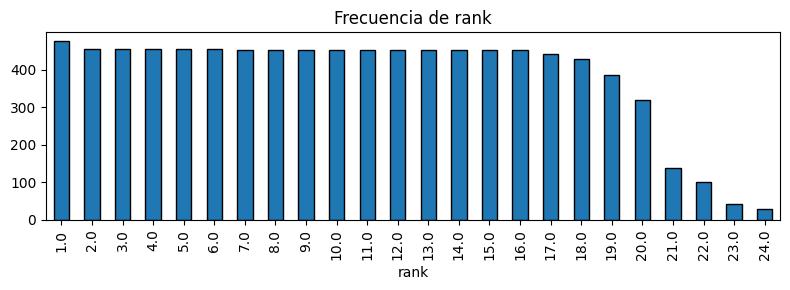

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. RECOLECCIÓN Y CARGA INICIAL (Sección 2.1 y 3.1)
# Usamos la URL raw de GitHub para poder descargar los archivos directamente
ruta = "https://raw.githubusercontent.com/Gizech-19/Data-Mining-Project-F1/main/"
archivos = ["lap_times.csv", "results.csv", "races.csv", "circuits.csv", "pit_stops.csv", "status.csv"]

print("--- Información volumétrica de archivos ---")
for archivo in archivos:
    ruta_completa = ruta + archivo
    # Leemos el archivo directamente desde la URL corregida
    df_temp = pd.read_csv(ruta_completa, na_values=r"\N")
    # Nota: os.path.getsize no funciona con URLs de internet.
    print(f"{archivo:15s} | Filas: {df_temp.shape[0]:7d} | Columnas: {df_temp.shape[1]:2d}")

# Carga con reconocimiento de datos nulos
lap_times = pd.read_csv(ruta + "lap_times.csv", na_values=r"\N")
results   = pd.read_csv(ruta + "results.csv", na_values=r"\N")
races     = pd.read_csv(ruta + "races.csv", na_values=r"\N")
circuits  = pd.read_csv(ruta + "circuits.csv", na_values=r"\N")
pit_stops = pd.read_csv(ruta + "pit_stops.csv", na_values=r"\N")
status    = pd.read_csv(ruta + "status.csv", na_values=r"\N")

# 2. INTEGRACIÓN RELACIONAL PARA EXPLORACIÓN (Sección 3.2 y 4)
# Unir results con races (año, circuito) y status (motivo de abandono)
df_resultados = (
    results
    .merge(races[["raceId", "year", "round", "circuitId", "name"]], on="raceId", how="left")
    .merge(circuits[["circuitId", "circuitRef", "country", "alt"]], on="circuitId", how="left")
    .merge(status, on="statusId", how="left")
)

# 3. Exploracion de los datos
  # 3.1 Analisis univariable
results.dtypes
results.nunique()

num_results = ["grid","positionOrder","points","laps","milliseconds","fastestLapSpeed","fastestLap"]
cat_results = ["status","number","rank"]

def analisis_univariable(df, num_cols, cat_cols):
  resumen = {}
  for col in num_cols:
    valores = pd.to_numeric(df[col], errors="coerce").dropna()
    resumen[col] = {
        "conteo": valores.count(),
        "min": valores.min(),
        "max": valores.max(),
        "media": valores.mean(),
        "mediana": valores.median(),
        "moda": ", ".join(map(str, valores.mode().tolist())),
        "rango": valores.max() - valores.min(),
        "Q1": valores.quantile(0.25),
        "Q2": valores.quantile(0.50),
        "Q3": valores.quantile(0.75),
        "IQR": valores.quantile(0.75) - valores.quantile(0.25),
        "varianza": valores.var(),
        "desviacion_estandar": valores.std()
    }
    rango = valores.max() - valores.min()
    es_entero = (valores % 1 == 0).all()
    bins = range(int(valores.min()), int(valores.max()) + 2) if es_entero and rango <= 100 else 30

    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    ax[0].hist(valores, bins=bins, edgecolor="black")
    ax[0].set_title(f"Histograma de {col}")
    ax[1].boxplot(valores, vert=False,
                  flierprops={"marker": "o", "markersize": 3, "markerfacecolor": "red", "alpha": 0.4})
    ax[1].set_title(f"Boxplot de {col}")
    plt.tight_layout()
    plt.show()

  display(pd.DataFrame(resumen).round(2))

  for col in cat_cols:
    conteo = df[col].value_counts()
    if col == "rank":
      conteo = conteo.sort_index()
    else:
      conteo = conteo.head(15)
    porcentaje = (df[col].value_counts(normalize=True) * 100).round(2)
    tabla = pd.DataFrame({"frecuencia": conteo, "%": porcentaje.loc[conteo.index]})
    print(f"\n====== Atributo: {col} ======\n")
    display(tabla)
    conteo.plot(kind="bar", figsize=(8, 3), title=f"Frecuencia de {col}", edgecolor="black")
    plt.tight_layout()
    plt.show()

analisis_univariable(df_resultados, num_results, cat_results)